<a href="https://colab.research.google.com/github/Alfredosernas/Deep-Learning/blob/main/Hands-on%205%3A%20Convolutional%20Neural%20Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Implementacion paso a paso de una CNN con el Dataset MINIST


Este Tutorial esta basado en el **Dataset MNIST** (Modified National IStirure of Standards and Tecnology): un total de **70,000** imagnes en esccala de grises de **28 X 28 pixeles**
repartidas en **10 clases** (digitos manuscritos del 0 al 9), divididas en **60,000 imagenes de entrenamiento** y **10,000 de prueba** con la intensidad originales en [0,255] normalizadas a [0,1] meidiante 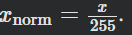.


# 1. Fundamentos Teoricos
Dado un conjunto de datos  $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{N}$ con N = 70,000,donde cada patron es $x_i \in \mathbb{R}^{28 \times 28}$  y cada etiqueta es $y_i \in \{0, 1, 2, 3, 4, 5, 6, 7, 8, 9\}$,una **Red Neuronal Convolucional (CNN)** aprovecha la estructura especial 2D de los digitos manuscritos mediante filtros compartidos y reduccion jerarquica.
## operacione matematicas claves
1. **Convolucion discreta 2 (correlacion cruzada)**
Dado un mapa de entrada X de dimenciones HXW y un kernel K de tamaño $k_h \times k_w$ con sesgo $b$:
$$(X * K)(i, j) = \sum_{m=0}^{k_h - 1} \sum_{n=0}^{k_w - 1} X(i + m,\; j + n) \cdot K(m, n) + b$$
Para una entrada cuadrada de tamaño N, Kernel de tamaño $K_f$, *stride* $s$ y padding p, la dimension escaial de salida es:
$$N_{\text{out}} = \left\lfloor \frac{N + 2p - K_f}{s} \right\rfloor + 1$$
2. **Función de activación ReLU (*Rectified Linear Unit*):**  
   Introduce no linealidad sobre los mapas de activación:

   $$f(z) = \max(0, z)$$

   Su derivada respecto a $z$ es $1$ si $z > 0$ y $0$ si $z \le 0$, evitando el desvanecimiento del gradiente en regiones activas.

3. **Max Pooling:**  
   Aplica una ventana deslizante (habitualmente $2 \times 2$ con *stride* $2$) y conserva el valor máximo de cada región, reduciendo dimensiones espaciales y aportando invarianza local ante pequeñas traslaciones del trazo:

   $$P(i, j) = \max_{0 \le m < k_h,\; 0 \le n < k_w} X(s \cdot i + m,\; s \cdot j + n)$$

4. **Flattening (Aplanamiento):**  
   Transforma un tensor tridimensional de forma $(h, w, c)$ en un vector unidimensional de longitud $h \times w \times c$ para conectarlo a capas totalmente conectadas.

5. **Capa Dense (Completamente conectada) y Softmax:**  
   Cada capa densa calcula:

   $$\mathbf{h} = \sigma(\mathbf{W}\mathbf{x} + \mathbf{b})$$

   En la capa de salida con $C = 10$ dígitos, **Softmax** transforma los *logits* $z_c$ en probabilidades que suman $1$:

   $$P(y = c \mid \mathbf{x}) = \frac{e^{z_c}}{\sum_{j=1}^{C} e^{z_j}}$$

6. **Función de pérdida (*Sparse Categorical Crossentropy*) y optimización Adam:**  
   Para etiquetas enteras $y_{\text{true}} \in \{0, \dots, 9\}$, la pérdida es:

   $$\mathcal{L} = -\log\left(\hat{y}_{y_{\text{true}}}\right)$$

   El optimizador **Adam** actualiza los parámetros $\theta$ mediante momentos adaptativos corregidos por sesgo ($\hat{m}_t, \hat{v}_t$):

   $$\theta_{t+1} = \theta_t - \eta \cdot \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

#2. Preparacion del Entorno y carga del Dataset MNIST
Cargamos MNISt desde tf.keras.datasets.mnist.load_data(): 60,000 imagenes de entrenamiento (train) y 10,000 de prueba (test) de 28 x 28 pixeles en scala de grises.Normalizamos las intensidades de [0,255] a [0,1] mediante  $x_{\text{norm}} = \frac{x}{255}$ damos forma tensorial (n,28,28,1)

Versión de TensorFlow: 2.21.0
GPUs disponibles: []
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Total de imágenes: 70000 | Train: 60000 (85.7%) | Test: 10000 (14.3%)
x_train shape: (60000, 28, 28, 1) | y_train shape: (60000,)
x_test shape : (10000, 28, 28, 1) | y_test shape : (10000,)


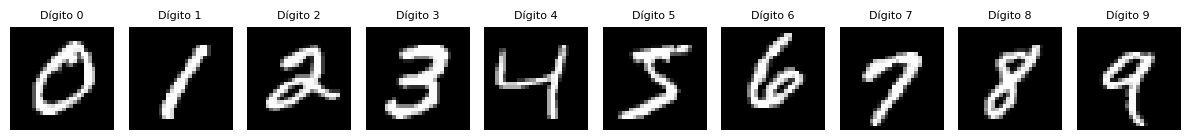

In [1]:
# Importamos las librerías necesarias para deep learning, álgebra lineal y visualización
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

# Fijamos una semilla aleatoria para garantizar reproducibilidad en Google Colab
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Verificamos versión de TensorFlow y disponibilidad de GPU en Colab
print("Versión de TensorFlow:", tf.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))

# Cargamos el dataset MNIST (N = 70,000: 60,000 train y 10,000 test, cada uno de 28x28)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Clases correspondientes a los 10 dígitos manuscritos (0-9)
class_names = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

# Normalizamos píxeles de [0, 255] a [0, 1] con la fórmula x_norm = x / 255
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Añadimos la dimensión de canal (1 canal en escala de grises) -> forma (N, 28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Verificamos dimensiones de entrada y etiquetas
total_samples = len(x_train) + len(x_test)
print(f"Total de imágenes: {total_samples} | Train: {len(x_train)} ({len(x_train)/total_samples*100:.1f}%) | "
      f"Test: {len(x_test)} ({len(x_test)/total_samples*100:.1f}%)")
print("x_train shape:", x_train.shape, "| y_train shape:", y_train.shape)
print("x_test shape :", x_test.shape,  "| y_test shape :", y_test.shape)

# Visualizamos un ejemplo de cada dígito (0 a 9) del conjunto de entrenamiento
plt.figure(figsize=(12, 2.5))
for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    plt.subplot(1, 10, digit + 1)
    plt.imshow(x_train[idx].squeeze(), cmap="gray")
    plt.title(f"Dígito {class_names[digit]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

#3. Etapa de Convolucion
La capa Conv2D aplica filtros (Kernels) de 3 x 3 sobre la matriz de intensidades 28 x 28 (1 canal) para extraer patrones locales como bordes,curvas y trazos de los digitos manuscritos. Con padding='same', se mantiene la resolucion especial 28 x 28.


In [3]:
# Definimos una capa Conv2D con 32 filtros de 3x3 y padding='same' para conservar 28x28
conv_demo = layers.Conv2D(
    filters=32,            # Cantidad de filtros (32 mapas de características de salida)
    kernel_size=(3, 3),    # Tamaño espacial del kernel: 3x3 píxeles
    strides=(1, 1),        # Desplazamiento de 1 píxel en alto y ancho
    padding="same",        # Relleno con ceros para mantener dimensiones 28x28
    name="conv_demo"
)

# Tomamos una imagen de ejemplo con dimensión de lote (batch): forma (1, 28, 28, 1)
sample_image = x_train[:1]

# Ejecutamos la convolución sobre la imagen de entrada
conv_output = conv_demo(sample_image)

print("Forma de entrada :", sample_image.shape)
print("Forma tras Conv2D:", conv_output.shape)  # Esperado: (1, 28, 28, 32)

Forma de entrada : (1, 28, 28, 1)
Forma tras Conv2D: (1, 28, 28, 32)


#4. Etapa de ReLU
La activacion ReLU ($f(z) = \max(0, z)$) se aplica sobre los mapas de caracteristicas generados por conv2d, conservando los valores positivos y fijando en 0 los valores negativos.


Forma tras ReLU: (1, 28, 28, 32)
Valor mínimo antes de ReLU  : -0.5128752589225769
Valor mínimo después de ReLU: 0.0


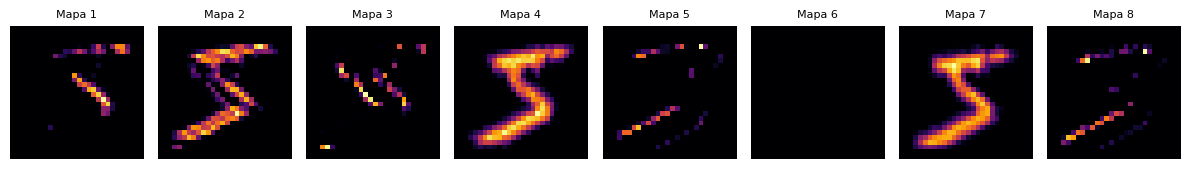

In [4]:
# Creamos la capa de activación no lineal ReLU
relu_demo = layers.ReLU(name="relu_demo")

# Aplicamos ReLU sobre los mapas de características convolucionales
relu_output = relu_demo(conv_output)

print("Forma tras ReLU:", relu_output.shape)
print("Valor mínimo antes de ReLU  :", float(tf.reduce_min(conv_output)))
print("Valor mínimo después de ReLU:", float(tf.reduce_min(relu_output)))

# Visualizamos los primeros 8 mapas de características tras aplicar ReLU
plt.figure(figsize=(12, 2.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(relu_output[0, :, :, i].numpy(), cmap="inferno")
    plt.title(f"Mapa {i+1}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

# 5. Etapa de MAx Pooling
La capa MaxPooling2d recorre los mapas activados con una ventana de 2 x 2 y stride 2, seleccionando el valor maximo de cada region. Esto reduce las dimensiones espaciales de 28 x 28 a 14 x 14 y aporta invarianza local ante pequelas variaciones en la pisicion del digito.


In [5]:
# Creamos una capa MaxPooling2D con ventana 2x2 y stride 2
max_pool_demo = layers.MaxPooling2D(
    pool_size=(2, 2),     # Ventana de 2x2 para tomar el máximo local
    strides=2,             # Avanza de 2 en 2 -> reduce dimensiones espaciales a la mitad
    padding="valid",       # Sin relleno adicional
    name="max_pool_demo"
)

# Aplicamos Max Pooling a la salida de ReLU
pool_output = max_pool_demo(relu_output)

print("Forma antes de Max Pooling  :", relu_output.shape)  # (1, 28, 28, 32)
print("Forma después de Max Pooling:", pool_output.shape)  # (1, 14, 14, 32)

Forma antes de Max Pooling  : (1, 28, 28, 32)
Forma después de Max Pooling: (1, 14, 14, 32)


#6.Etapa de Flattening
La capa Flatten convierte el volumen 3D (h,w,c) de cada imagen en un vector 1d de longitud h x w x c, permitiendo conectarlo a las capas densas de clasificacion.


In [6]:
# Definimos la capa Flatten
flatten_demo = layers.Flatten(name="flatten_demo")

# Aplanamos el tensor 3D obtenido tras Max Pooling
flat_output = flatten_demo(pool_output)

print("Forma antes de Flatten  :", pool_output.shape)  # (1, 14, 14, 32)
print("Forma después de Flatten:", flat_output.shape)  # (1, 6272)

Forma antes de Flatten  : (1, 14, 14, 32)
Forma después de Flatten: (1, 6272)


#7. Etapa de Dense ( y Entrenamiento de la CNN)
Las capas Dense integran la informacion espacial extraida:


*   Una capa Dense oculta (128 unidades con ReLU ) aprende combinaciones no lineales de los rasgos
*   Dropout(0.3) apaga aleatoriamente el 30% de las neuronas ocultas durante el entrenamiento para prevenir el sobreajuste.
*   La capa Dense de salida tiene 10 neuronas (digitos 0-9) con activacion softmax.

Ensablamos la CNN completa con dos bloques de Concolucion ->ReLU -> MAX Pooling, seguida de Flattening y Dense, y la entrenamos sobre las 60,000 imagenes de entrenamiento de MNIST.




Forma antes de Flatten  : (1, 14, 14, 32)
Forma después de Flatten: (1, 6272)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling_1 (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling_2 (MaxPooling2D)    │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flattening (Flatten)            │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (ReLU)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_output (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 42ms/step - accuracy: 0.9419 - loss: 0.1886 - val_accuracy: 0.9855 - val_loss: 0.0491
Epoch 2/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 43ms/step - accuracy: 0.9813 - loss: 0.0616 - val_accuracy: 0.9890 - val_loss: 0.0393
Epoch 3/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9864 - loss: 0.0433 - val_accuracy: 0.9902 - val_loss: 0.0358
Epoch 4/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 50ms/step - accuracy: 0.9895 - loss: 0.0327 - val_accuracy: 0.9900 - val_loss: 0.0387
Epoch 5/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 76s 43ms/step - accuracy: 0.9910 - loss: 0.0275 - val_accuracy: 0.9912 - val_loss: 0.0318
Epoch 6/6
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.9925 - loss: 0.0232 - val_accuracy: 0.9890 - val_loss: 0.0414


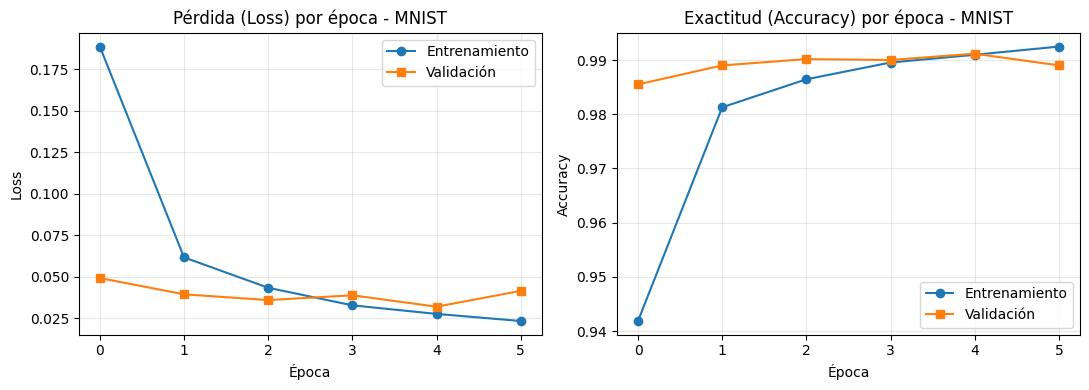

In [9]:
# Construimos el modelo CNN secuencial integrando todas las etapas requeridas
mnist_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1), name="input_mnist"),

    # --- Bloque 1: Convolución -> ReLU -> Max Pooling ---
    layers.Conv2D(32, kernel_size=(3, 3), padding="same", name="conv_1"),
    layers.ReLU(name="relu_1"),
    layers.MaxPooling2D(pool_size=(2, 2), name="max_pooling_1"),  # (28, 28, 32) -> (14, 14, 32)

    # --- Bloque 2: Convolución -> ReLU -> Max Pooling ---
    layers.Conv2D(64, kernel_size=(3, 3), padding="same", name="conv_2"),
    layers.ReLU(name="relu_2"),
    layers.MaxPooling2D(pool_size=(2, 2), name="max_pooling_2"),  # (14, 14, 64) -> (7, 7, 64)

    # --- Etapa Flattening ---
    layers.Flatten(name="flattening"),                                # (7, 7, 64) -> (3136,)

    # --- Etapa Dense (oculta + regularización + capa de salida) ---
    layers.Dense(128, name="dense_hidden"),
    layers.ReLU(name="relu_dense"),
    layers.Dropout(0.3, name="dropout"),                             # Regularización durante el entrenamiento
    layers.Dense(10, activation="softmax", name="dense_output")      # 10 clases (dígitos 0 a 9)
])

# Mostramos resumen de arquitectura y parámetros
mnist_cnn.summary()

# Compilamos con Adam, pérdida sparse_categorical_crossentropy y métrica accuracy
mnist_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenamos sobre x_train (60,000 imágenes) reservando 10% para validación
history = mnist_cnn.fit(
    x_train, y_train,
    batch_size=64,
    epochs=6,
    validation_split=0.1,
    verbose=1
)

# Graficamos evolución de pérdida y exactitud en entrenamiento y validación
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(history.history["loss"], marker="o", label="Entrenamiento")
ax1.plot(history.history["val_loss"], marker="s", label="Validación")
ax1.set_title("Pérdida (Loss) por época - MNIST")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history["accuracy"], marker="o", label="Entrenamiento")
ax2.plot(history.history["val_accuracy"], marker="s", label="Validación")
ax2.set_title("Exactitud (Accuracy) por época - MNIST")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#8. Etapa de Evaluacion
Evaluamos el modelo entrenado sobre las 10,000 imagenes de prueba (test) de MNIST (x_test, y_test) y obtenemos el reporte detallado por digito (0-9).

In [10]:
# Evaluamos pérdida y exactitud en el conjunto de prueba (10,000 imágenes)
test_loss, test_accuracy = mnist_cnn.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

# Obtenemos probabilidades predichas y clase predicha (índice de mayor probabilidad)
y_test_probs = mnist_cnn.predict(x_test, verbose=0)
y_test_pred = np.argmax(y_test_probs, axis=1)

# Mostramos precisión, recall y F1-score para cada dígito (0 a 9)
print("\nReporte de clasificación por dígito:")
print(classification_report(y_test, y_test_pred, target_names=class_names, digits=4))

Test Loss     : 0.0280
Test Accuracy : 0.9902 (99.02%)

Reporte de clasificación por dígito:
              precision    recall  f1-score   support

           0     0.9959    0.9969    0.9964       980
           1     0.9887    0.9982    0.9934      1135
           2     0.9942    0.9893    0.9917      1032
           3     0.9882    0.9950    0.9916      1010
           4     0.9959    0.9847    0.9903       982
           5     0.9888    0.9888    0.9888       892
           6     0.9926    0.9864    0.9895       958
           7     0.9951    0.9835    0.9892      1028
           8     0.9798    0.9959    0.9878       974
           9     0.9831    0.9822    0.9826      1009

    accuracy                         0.9902     10000
   macro avg     0.9902    0.9901    0.9901     10000
weighted avg     0.9902    0.9902    0.9902     10000



#9. Etapa de Prediccion
Realizamos predicciones nuevas sobre nuevas imagenes del conjunto de prueba (x_test),mostrando el digito predicho, la confianza porcentual de softmax y la etiqueta real.


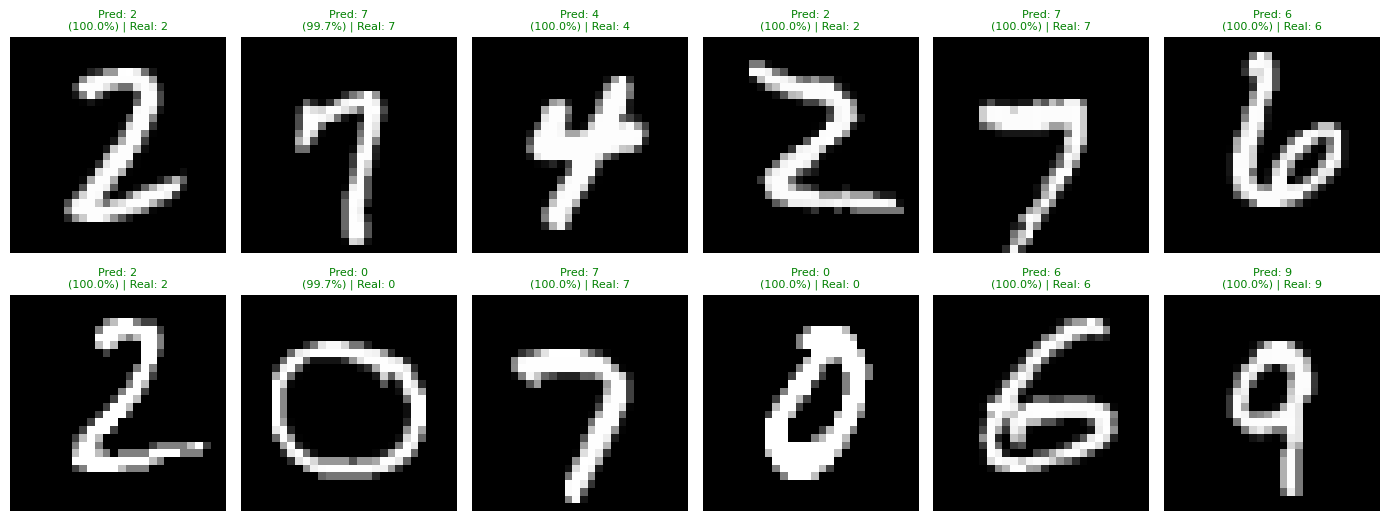

Imagen índice 4385 -> Predicción: 2 (100.00% de confianza) | Etiqueta real: 2


In [11]:
# Seleccionamos 12 imágenes aleatorias del conjunto de prueba para predecir
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(x_test), size=12, replace=False)

sample_x = x_test[sample_indices]
sample_y = y_test[sample_indices]

# Ejecutamos inferencia con el modelo entrenado
pred_probs = mnist_cnn.predict(sample_x, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)

# Visualizamos cada imagen con su predicción, porcentaje de confianza y dígito real
plt.figure(figsize=(14, 5.5))
for i, idx in enumerate(sample_indices):
    plt.subplot(2, 6, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")

    pred_digit = class_names[pred_classes[i]]
    true_digit = class_names[sample_y[i]]
    confidence = pred_probs[i, pred_classes[i]] * 100.0

    # Verde si acierta, rojo si predice una clase distinta a la real
    title_color = "green" if pred_classes[i] == sample_y[i] else "red"
    plt.title(f"Pred: {pred_digit}\n({confidence:.1f}%) | Real: {true_digit}", fontsize=8, color=title_color)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Predicción sobre una única imagen individual
single_idx = int(sample_indices[0])
single_img = np.expand_dims(x_test[single_idx], axis=0)  # Forma (1, 28, 28, 1)
single_probs = mnist_cnn.predict(single_img, verbose=0)[0]
best_digit = int(np.argmax(single_probs))

print(f"Imagen índice {single_idx} -> Predicción: {best_digit} "
      f"({single_probs[best_digit]*100:.2f}% de confianza) | Etiqueta real: {y_test[single_idx]}")